# Ames House Price Prediction
We train three regressors on the labelled Ames houses, check their predictions on held-out sales, and estimate prices for the competition test houses. Attach **Traindata** and **testData**, then run the cells in order. The submission contains one price per test Id.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from xgboost import XGBRegressor
from catboost import CatBoostRegressor

## Read the houses
We identify each Ames CSV by its columns. Only the training file has the sale price. We preserve the literal category `None` because it can describe an absent facility.

In [2]:
inputs = Path("/kaggle/input")
output = Path("/kaggle/working")
if not inputs.exists() and Path("../input").is_dir():
    inputs = Path("../input")
    output = Path.cwd()
if not inputs.exists():
    inputs = Path("Dataset")
    output = Path("kaggle_outputs")

files = {"train": [], "test": []}
for path in inputs.rglob("*"):
    if path.suffix.lower() == ".csv":
        columns = pd.read_csv(path, nrows=0).columns
        if {"Id", "GrLivArea", "Neighborhood", "OverallQual"}.issubset(columns):
            group = "train" if "SalePrice" in columns else "test"
            files[group].append(path)
if len(files["train"]) != 1 or len(files["test"]) != 1:
    raise ValueError("Attach one complete Ames training CSV and one test CSV.")
train = pd.read_csv(files["train"][0], keep_default_na=False, na_values=["", "NA"])
test = pd.read_csv(files["test"][0], keep_default_na=False, na_values=["", "NA"])
assert train.Id.notna().all() and test.Id.notna().all()
assert train.Id.is_unique and test.Id.is_unique
assert set(train.Id).isdisjoint(test.Id)
assert set(train.columns) - {"SalePrice"} == set(test.columns)
assert train.SalePrice.gt(0).all()
display(train.head(3))
print(len(train), "training houses;", len(test), "test houses")

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500


1460 training houses; 1459 test houses


## What do we know before fitting a model?
We check the target scale, the meaning of missing values, and the relationships among size, quality and location. All price comparisons in this section use labelled houses.

Predictors: 79


,Columns
object,43
int64,33
float64,3


,SalePrice,GrLivArea,TotalBsmtSF,OverallQual,YearBuilt
count,1460.0,1460.0,1460.0,1460.0,1460.0
mean,180921.2,1515.5,1057.4,6.1,1971.3
std,79442.5,525.5,438.7,1.4,30.2
min,34900.0,334.0,0.0,1.0,1872.0
25%,129975.0,1129.5,795.8,5.0,1954.0
50%,163000.0,1464.0,991.5,6.0,1973.0
75%,214000.0,1776.8,1298.2,7.0,2000.0
max,755000.0,5642.0,6110.0,10.0,2010.0


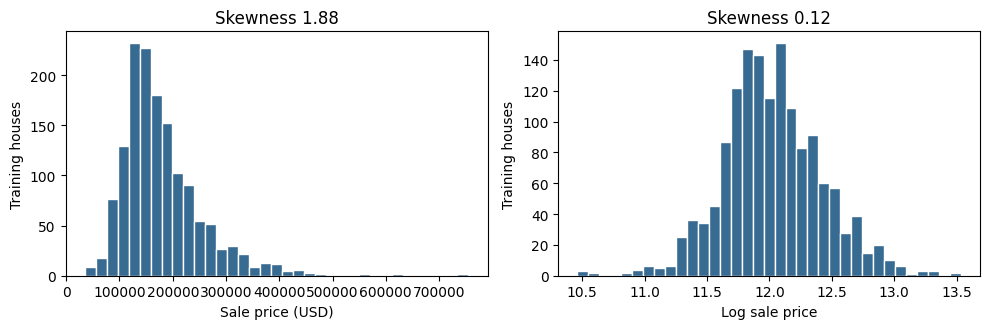

In [3]:
features = train.drop(columns=["Id", "SalePrice"])
print("Predictors:", features.shape[1])
display(features.dtypes.astype(str).value_counts().to_frame("Columns"))
display(
    train[["SalePrice", "GrLivArea", "TotalBsmtSF", "OverallQual", "YearBuilt"]]
    .describe()
    .round(1)
)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for axis, values, label in zip(
    ax, [train.SalePrice, np.log(train.SalePrice)], ["Sale price (USD)", "Log sale price"]
):
    axis.hist(values, bins=35, color="#386b92", edgecolor="white")
    axis.set(xlabel=label, ylabel="Training houses", title=f"Skewness {values.skew():.2f}")
plt.tight_layout()
plt.show()

A few expensive sales stretch the upper end of the raw distribution. Taking logs brings the skewness down from 1.88 to 0.12. We fit log price and measure validation error on that same scale.

### Which blanks describe a missing facility?
A blank basement description has two possible meanings. Zero basement area supports absence. A positive area tells us a basement exists even if its description is missing.

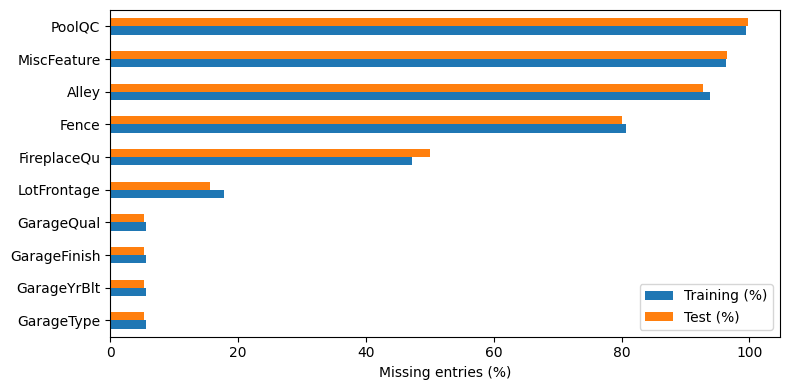

,Missing field,Blank rows,Zero amount,Positive amount,Unknown amount
0,PoolQC,1453,1453,0,0
1,FireplaceQu,690,690,0,0
2,BsmtQual,37,37,0,0
3,GarageQual,81,81,0,0


In [4]:
missing = pd.DataFrame(
    {
        "Training (%)": features.isna().mean() * 100,
        "Test (%)": test[features.columns].isna().mean() * 100,
    }
)
top = missing.max(axis=1).nlargest(10).index
missing.loc[top].sort_values("Training (%)").plot.barh(
    figsize=(8, 4), xlabel="Missing entries (%)"
)
plt.tight_layout()
plt.show()
checks = []
for field, amount in [
    ("PoolQC", "PoolArea"),
    ("FireplaceQu", "Fireplaces"),
    ("BsmtQual", "TotalBsmtSF"),
    ("GarageQual", "GarageArea"),
]:
    blank = train.loc[train[field].isna(), amount]
    checks.append(
        [field, len(blank), (blank == 0).sum(), (blank > 0).sum(), blank.isna().sum()]
    )
display(
    pd.DataFrame(
        checks,
        columns=[
            "Missing field",
            "Blank rows",
            "Zero amount",
            "Positive amount",
            "Unknown amount",
        ],
    )
)

### Where does floor area explain price, and where does it fail?
We look at the typical relationship as well as the houses a model might overprice. The neighbourhood chart uses the eight largest groups so each box has a useful number of sales.

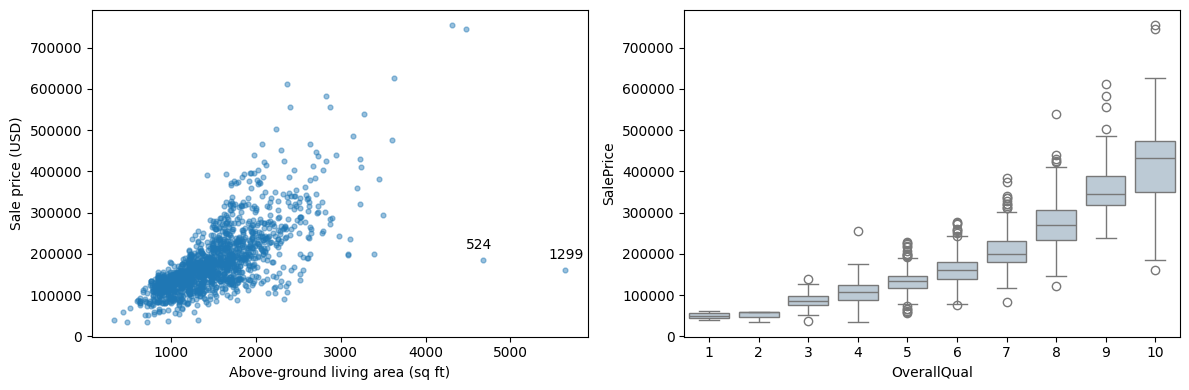

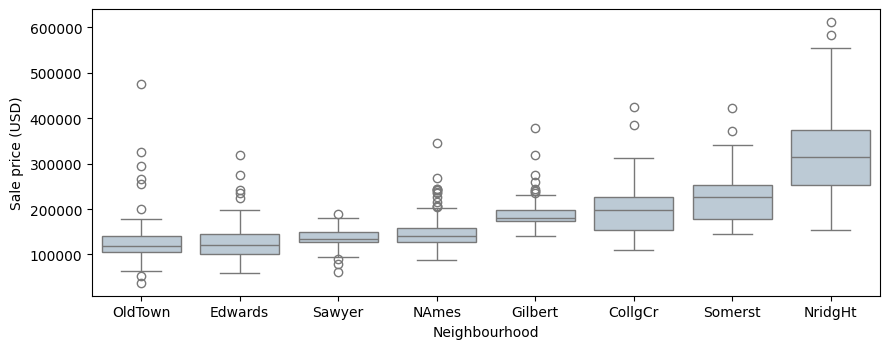

,Id,GrLivArea,OverallQual,Neighborhood,SaleCondition,SalePrice
523,524,4676,10,Edwards,Partial,184750
1298,1299,5642,10,Edwards,Partial,160000


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(train.GrLivArea, train.SalePrice, s=12, alpha=0.45)
unusual = train[(train.GrLivArea > 4000) & (train.SalePrice < 200000)]
for _, house in unusual.iterrows():
    ax[0].annotate(
        str(int(house.Id)),
        (house.GrLivArea, house.SalePrice),
        xytext=(-12, 8),
        textcoords="offset points",
    )
ax[0].set(xlabel="Above-ground living area (sq ft)", ylabel="Sale price (USD)")
sns.boxplot(data=train, x="OverallQual", y="SalePrice", ax=ax[1], color="#b8cbd9")
plt.tight_layout()
plt.show()
areas = train.Neighborhood.value_counts().head(8).index
local = train[train.Neighborhood.isin(areas)]
order = local.groupby("Neighborhood").SalePrice.median().sort_values().index
fig, ax = plt.subplots(figsize=(9, 3.6))
sns.boxplot(data=local, x="Neighborhood", y="SalePrice", order=order, ax=ax, color="#b8cbd9")
ax.set(xlabel="Neighbourhood", ylabel="Sale price (USD)")
plt.tight_layout()
plt.show()
display(
    unusual[["Id", "GrLivArea", "OverallQual", "Neighborhood", "SaleCondition", "SalePrice"]]
)

Houses 524 and 1299 exceed 4,600 square feet and both sold below $200,000. We keep their prices in the training data. They motivate limiting extreme input values for SVR and checking comparable sales at the end. Prices vary within each quality grade and across neighbourhoods, so we keep location and give the models a quality-by-area feature.

### Which measurements overlap?
We examine correlations among the measurements we use to build features. Garage capacity and garage area both describe garage size. Floor and basement areas describe different parts of the same house. We keep the individual measurements and also give the models an indoor-area total.

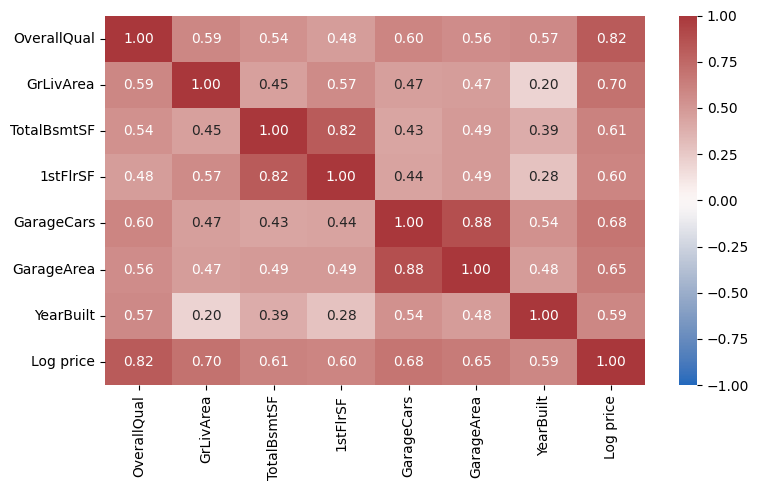

In [6]:
measurements = train[
    [
        "OverallQual",
        "GrLivArea",
        "TotalBsmtSF",
        "1stFlrSF",
        "GarageCars",
        "GarageArea",
        "YearBuilt",
    ]
].copy()
measurements["Log price"] = np.log(train.SalePrice)
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(
    measurements.corr(), annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax
)
plt.tight_layout()
plt.show()

## Prepare the housing features
We use the same row-wise rules for every house. We check facility measurements before filling missing descriptions, calculate ages at the sale date, and combine related measurements into total area and bathrooms. The validation loop learns medians, category frequencies, clipping limits and scales from the training households in each fold.

In [7]:
def make_features(frame):
    d = frame.copy()
    for c in ["YearBuilt", "YearRemodAdd", "GarageYrBlt"]:
        d.loc[(d[c] < 1800) | (d[c] > d.YrSold + 1), c] = np.nan
    no_basement = d.TotalBsmtSF.eq(0)
    no_garage = d.GarageCars.eq(0) & d.GarageArea.eq(0)
    absence = {
        "Alley": pd.Series(True, index=d.index),
        "Fence": pd.Series(True, index=d.index),
        "MiscFeature": d.MiscVal.eq(0),
        "PoolQC": d.PoolArea.eq(0),
        "FireplaceQu": d.Fireplaces.eq(0),
        "MasVnrType": d.MasVnrArea.eq(0),
    }
    for c in ["BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]:
        absence[c] = no_basement
    for c in ["GarageType", "GarageFinish", "GarageQual", "GarageCond"]:
        absence[c] = no_garage
    for c, mask in absence.items():
        d.loc[mask & d[c].isna(), c] = "None"
    for c in ["BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "BsmtFullBath", "BsmtHalfBath"]:
        d.loc[no_basement & d[c].isna(), c] = 0
    d.loc[d.MasVnrType.eq("None") & d.MasVnrArea.isna(), "MasVnrArea"] = 0
    for c in ["MSSubClass", "MoSold"]:
        d[c] = d[c].astype(str)
    d["HouseAge"] = (d.YrSold - d.YearBuilt).clip(lower=0)
    d["RemodelAge"] = (d.YrSold - d.YearRemodAdd).clip(lower=0)
    d["GarageAge"] = (d.YrSold - d.GarageYrBlt).clip(lower=0)
    d.loc[no_garage, "GarageAge"] = 0
    d = d.drop(columns="GarageYrBlt")
    d["TotalSF"] = d.TotalBsmtSF + d["1stFlrSF"] + d["2ndFlrSF"]
    d["FinishedSF"] = d.GrLivArea + d.BsmtFinSF1 + d.BsmtFinSF2
    d["TotalBath"] = d.FullBath + 0.5 * d.HalfBath + d.BsmtFullBath + 0.5 * d.BsmtHalfBath
    d["TotalOutdoorSF"] = (
        d.WoodDeckSF + d.OpenPorchSF + d.EnclosedPorch + d["3SsnPorch"] + d.ScreenPorch
    )
    for source, name in [
        ("GarageArea", "HasGarage"),
        ("TotalBsmtSF", "HasBasement"),
        ("Fireplaces", "HasFireplace"),
        ("PoolArea", "HasPool"),
        ("2ndFlrSF", "HasSecondFloor"),
    ]:
        d[name] = np.where(d[source].isna(), np.nan, d[source].gt(0).astype(float))
    d["WasRemodeled"] = (d.YearRemodAdd != d.YearBuilt).astype(int)
    d["IsNew"] = (d.YearBuilt >= d.YrSold).astype(int)
    quality = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
    for c in [
        "ExterQual",
        "ExterCond",
        "BsmtQual",
        "BsmtCond",
        "HeatingQC",
        "KitchenQual",
        "FireplaceQu",
        "GarageQual",
        "GarageCond",
        "PoolQC",
    ]:
        d[c] = d[c].map(quality)
    d["BsmtExposure"] = d.BsmtExposure.map({"None": 0, "No": 0, "Mn": 1, "Av": 2, "Gd": 3})
    d["GarageFinish"] = d.GarageFinish.map({"None": 0, "Unf": 1, "RFn": 2, "Fin": 3})
    for c in ["BsmtFinType1", "BsmtFinType2"]:
        d[c] = d[c].map({"None": 0, "Unf": 1, "LwQ": 2, "Rec": 3, "BLQ": 4, "ALQ": 5, "GLQ": 6})
    # A few explicit interactions, without generating all feature pairs.
    d["QualityLivingArea"] = d.OverallQual * np.log1p(d.GrLivArea)
    d["QualityTotalArea"] = d.OverallQual * np.log1p(d.TotalSF)
    d["QualityHouseAge"] = d.OverallQual * d.HouseAge
    d["TotalQuality"] = d.OverallQual + d.OverallCond
    return d

## Fit the three models
SVR uses scaled numerical inputs and a 99th-percentile cap on continuous measurements. XGBoost uses an uncapped view of the encoded features. CatBoost receives the categorical columns directly. We use the project's existing blend weights of 50% SVR, 10% XGBoost and 40% CatBoost on the log-price scale.

In [8]:
def fill_frontage(training, other):
    training = training.copy()
    other = other.copy()
    local_median = training.groupby("Neighborhood").LotFrontage.median()
    global_median = training.LotFrontage.median()
    for frame in [training, other]:
        frame["LotFrontage"] = frame.LotFrontage.fillna(
            frame.Neighborhood.map(local_median)
        ).fillna(global_median)
    return training, other


def numeric_inputs(training, other, cap):
    training = training.copy()
    other = other.copy()
    categories = training.select_dtypes(exclude="number").columns
    for col in categories:
        counts = training[col].value_counts()
        common = counts[counts >= 3].index
        for frame in [training, other]:
            frame[col] = frame[col].where(frame[col].isin(common), "Other")

    years = ["YearBuilt", "YearRemodAdd", "YrSold"]
    keep_scale = years + [
        "OverallQual",
        "OverallCond",
        "QualityLivingArea",
        "QualityTotalArea",
        "QualityHouseAge",
        "TotalQuality",
    ]
    for col in training.select_dtypes(include="number"):
        values = training[col]
        if (
            col not in keep_scale
            and values.nunique() > 10
            and values.min() >= 0
            and values.skew() > 0.75
        ):
            training[col] = np.log1p(training[col])
            other[col] = np.log1p(other[col])
        if cap and col not in years and training[col].nunique() > 20:
            limit = training[col].quantile(0.99)
            training[col] = training[col].clip(upper=limit)
            other[col] = other[col].clip(upper=limit)
    medians = training.median(numeric_only=True).fillna(0)
    training = pd.get_dummies(training.fillna(medians), columns=categories, dtype=float)
    other = pd.get_dummies(other.fillna(medians), columns=categories, dtype=float)
    return training, other.reindex(columns=training.columns, fill_value=0)

In [9]:
def predict_models(training, target, other):
    training, other = fill_frontage(training, other)
    categories = training.select_dtypes(exclude="number").columns.tolist()
    for frame in [training, other]:
        for col in categories:
            frame[col] = frame[col].fillna("Unknown").astype(str)

    train_svr, other_svr = numeric_inputs(training, other, cap=True)
    scaler = StandardScaler()
    svr = SVR(C=10, gamma=0.0001, epsilon=0.01)
    svr.fit(scaler.fit_transform(train_svr), target)
    svr_log = svr.predict(scaler.transform(other_svr))

    train_tree, other_tree = numeric_inputs(training, other, cap=False)
    xgb = XGBRegressor(
        n_estimators=2000,
        learning_rate=0.025,
        max_depth=3,
        min_child_weight=3,
        subsample=0.8,
        colsample_bytree=0.7,
        reg_lambda=3,
        reg_alpha=0.01,
        tree_method="hist",
        n_jobs=4,
        random_state=42,
    )
    xgb.fit(train_tree, target)
    xgb_log = xgb.predict(other_tree)

    cat = CatBoostRegressor(
        iterations=1800,
        depth=6,
        learning_rate=0.03,
        l2_leaf_reg=5,
        random_seed=42,
        thread_count=4,
        verbose=False,
        allow_writing_files=False,
    )
    cat.fit(training, target, cat_features=categories)
    cat_log = cat.predict(other)
    return pd.DataFrame(
        {
            "SVR": svr_log,
            "XGBoost": xgb_log,
            "CatBoost": cat_log,
            "Blend": 0.5 * svr_log + 0.1 * xgb_log + 0.4 * cat_log,
        },
        index=other.index,
    )

## Check held-out predictions
Each house gets one prediction from models fitted on the other four folds. The score below measures the blend before the final comparable-sale check. These folds also informed the project's model choices.

In [10]:
X = make_features(train.drop(columns=["Id", "SalePrice"]))
X_test = make_features(test.drop(columns="Id"))
y = np.log(train.SalePrice)
folds = KFold(n_splits=5, shuffle=True, random_state=42)
parts = []
for fit_rows, valid_rows in folds.split(X):
    part = predict_models(X.iloc[fit_rows], y.iloc[fit_rows], X.iloc[valid_rows])
    parts.append(part)
oof = pd.concat(parts).reindex(train.index)
assert oof.notna().all().all()
scores = np.sqrt(oof.sub(y, axis=0).pow(2).mean())
display(scores.to_frame("Five-fold log-RMSE").round(5))
display(
    pd.DataFrame(
        {"Id": train.Id, "Actual": train.SalePrice, "Held-out estimate": np.exp(oof.Blend)}
    )
    .loc[unusual.index]
    .round(0)
)

,Five-fold log-RMSE
SVR,0.12150
XGBoost,0.12652
CatBoost,0.12345
Blend,0.11797


,Id,Actual,Held-out estimate
523,524,184750,532690.0
1298,1299,160000,545754.0


## Refit on all sales and check comparable houses
We apply the report's narrow comparable-sale rule to the newly trained blend. A new house above 4,000 square feet must be recorded as incomplete at its last assessment. We then look for training sales of the same building type in the same neighbourhood, with comparable quality, living area and lot area.

In [11]:
test_predictions = predict_models(X, y, X_test)
prices = np.exp(test_predictions["Blend"]).copy()


def large_new_sales(frame):
    age = frame.YrSold - frame.YearBuilt
    return (
        frame.SaleCondition.eq("Partial")
        & frame.SaleType.eq("New")
        & frame.GrLivArea.gt(4000)
        & age.between(-1, 1)
    )


candidates = train[large_new_sales(train)]
matches = []
for index, house in test[large_new_sales(test)].iterrows():
    similar = candidates[
        candidates.Neighborhood.eq(house.Neighborhood)
        & candidates.BldgType.eq(house.BldgType)
        & (candidates.OverallQual - house.OverallQual).abs().le(1)
        & np.log(candidates.GrLivArea / house.GrLivArea).abs().le(0.25)
        & np.log(candidates.LotArea / house.LotArea).abs().le(0.60)
    ]
    if len(similar):
        before = prices.loc[index]
        reference = np.log(similar.SalePrice).median()
        prices.loc[index] = np.exp((np.log(before) + reference) / 2)
        matches.append([house.Id, similar.Id.tolist(), before, prices.loc[index]])
display(
    pd.DataFrame(
        matches, columns=["Test Id", "Comparable training Ids", "Before", "After"]
    ).round(2)
)

,Test Id,Comparable training Ids,Before,After
0,2550,"[524, 1299]",340447.0,241936.21


In [12]:
submission = pd.DataFrame({"Id": test.Id, "SalePrice": prices})
assert submission.Id.equals(test.Id)
assert np.isfinite(submission.SalePrice).all() and submission.SalePrice.gt(0).all()
output.mkdir(exist_ok=True, parents=True)
submission.to_csv(output / "submission.csv", index=False)
print("Saved", len(submission), "predictions to", output / "submission.csv")
display(submission.head())

Saved 1459 predictions to kaggle_outputs/submission.csv


,Id,SalePrice
0,1461,121187.070456
1,1462,164627.106001
2,1463,185616.269482
3,1464,196372.907703
4,1465,191511.392846
